# E4 failure analysis
This notebook rebuilds the four cached prediction variants on the test split.
It produces question-level evidence diagnostics and passage exports for inspection without new model calls.


## Rebuild and reconcile
Loads the cached contexts, scores, predictions, thresholds, and gold answers.
The copied E3 helpers come from cells 3, 5, 9, 11, and 17 of E3_ablation.ipynb; the scoring constants match E2_qwen_f1_filter.ipynb cell 4 exactly.


In [1]:
from pathlib import Path
import hashlib, json, random
from collections import Counter, defaultdict
import pandas as pd
import matplotlib.pyplot as plt

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "E2_Qwen_F1").exists():
    REPO_ROOT = REPO_ROOT.parent
E2_RESULTS = REPO_ROOT / "E2_Qwen_F1" / "results_e2_qwen_f1"
E3_RESULTS = REPO_ROOT / "E3_Ablation" / "results_e3_ablation"
E4_RESULTS = REPO_ROOT / "E4_Failure_Analysis" / "results_e4_failure_analysis"
E4_RESULTS.mkdir(parents=True, exist_ok=True)
def read_jsonl(path):
    if not path.exists():
        raise FileNotFoundError(path)
    return [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]

def read_json(path):
    if not path.exists():
        raise FileNotFoundError(path)
    return json.loads(path.read_text(encoding="utf-8"))

def row_key(row):
    return (row["condition"], str(row["id"]))

def context_hash(rows):
    text = "".join(json.dumps(row, ensure_ascii=False, sort_keys=True, separators=(",", ":")) + "\n" for row in rows)
    return hashlib.sha256(text.encode("utf-8")).hexdigest()

REFUSAL="I can not answer the question because of insufficient information in documents.";REFUSAL_KEY="insufficient information"
REFUSAL_PHRASES=[REFUSAL_KEY,"can not answer","cannot answer","unable to answer","cannot be answered","cannot be determined","cannot determine","does not provide","do not provide","doesn't provide","does not contain","do not contain","doesn't contain","does not specify","do not specify","doesn't specify","does not mention","do not mention","not mentioned","no information","no mention","none of the provided documents","none of the documents","not explicitly","not directly"]
HEDGE_MARKERS=["likely","probably","presumably","possibly","might","suggest","infer","implied","indicating","as indicated","assume","speculat","expected to","would be","would have","though"]
def contains(pred,ans):
 pred=pred.lower();ans=[ans] if isinstance(ans,str) else ans
 for part in ans:
  alts=part if isinstance(part,list) else [part]
  if not any(str(a).lower() in pred for a in alts):return False
 return True
def reject(pred):
 p=pred.lower()
 if REFUSAL_KEY in p:return True
 if not any(x in p for x in REFUSAL_PHRASES):return False
 return not (any(x in p for x in HEDGE_MARKERS))
def summarize(name,es,pm):
 co=re=wr=0
 for e in es:
  p=pm[(name,str(e["id"]))];ok=contains(p,e["answer"]);r=reject(p) and not ok;co+=ok;re+=r;wr+=not ok and not r
 if name=="incomplete":return {"n":len(es),"rejection_rate":re/max(1,len(es))}
 return {"n":len(es),"accuracy":co/max(1,len(es)),"rejection_rate":re/max(1,len(es)),"wrong_answer":wr/max(1,len(es))}
def bal(s):return (sum(s[n]["accuracy"] for n in ("noise_0.0","noise_0.4","noise_0.8"))/3+s["incomplete"]["rejection_rate"])/2
def label(condition, pred, answer):
    if condition == "incomplete":
        return "refused" if reject(pred) else "answered"
    if contains(pred, answer):
        return "correct"
    return "rejected" if reject(pred) else "wrong"

paths = {name: E2_RESULTS / name for name in (
    "shared_contexts.jsonl", "shared_contexts_manifest.json",
    "rgb_e2_passage_scores.jsonl", "rgb_e2_e0_predictions.jsonl",
    "rgb_e2_e2_predictions.jsonl", "rgb_e2_e2_predictions.jsonl.meta.json")}
contexts = read_jsonl(paths["shared_contexts.jsonl"])
manifest = read_json(paths["shared_contexts_manifest.json"])
scores = read_jsonl(paths["rgb_e2_passage_scores.jsonl"])
e0 = read_jsonl(paths["rgb_e2_e0_predictions.jsonl"])
e2 = read_jsonl(paths["rgb_e2_e2_predictions.jsonl"])
e2_meta = read_json(paths["rgb_e2_e2_predictions.jsonl.meta.json"])
metrics = read_json(E2_RESULTS / "rgb_e2_qwen_metrics.json")
tau = metrics["abstention_threshold"]
filter_threshold = e2_meta["filter_threshold"]
assert context_hash(contexts) == manifest["sha256_canonical_jsonl"]
assert len(contexts) == 1300
# Verify the exact numeric-ID split used by Baseline.
split_rng = random.Random(42)
numeric_calibration = {}
for split_condition in ("incomplete", "contradictory"):
    numeric_ids = sorted({int(r["id"]) for r in contexts if r["condition"] == split_condition})
    numeric_calibration[split_condition] = set(split_rng.sample(numeric_ids, int(0.3 * len(numeric_ids))))
for context in contexts:
    split_condition = "contradictory" if context["condition"] == "contradictory" else "incomplete"
    expected_split = "calibration" if int(context["id"]) in numeric_calibration[split_condition] else "test"
    assert context["split"] == expected_split, "Run E2 first to rebuild the numeric-ID split."

# Reattach the answer fields used by the reference notebook from its RGB inputs.
def read_json_records(path):
    return [json.loads(line) for line in Path(path).read_text(encoding="utf-8").splitlines() if line.strip()]

DATA = next(p for p in (REPO_ROOT / "RGB" / "data", REPO_ROOT.parent / "RGB" / "data") if (p / "en_refine.json").exists())
refine = read_json_records(DATA / "en_refine.json")
fact = read_json_records(DATA / "en_fact.json")
answers = {}
for condition in ("noise_0.0", "noise_0.4", "noise_0.8", "incomplete"):
    answers.update({(condition, str(row["id"])): row["answer"] for row in refine})
answers.update({("contradictory", str(row["id"])): row["answer"] for row in fact})
eval_rows = []
for row in contexts:
    item = dict(row)
    item["answer"] = answers[row_key(row)]
    eval_rows.append(item)

score_groups = defaultdict(list)
for row in scores:
    score_groups[row_key(row)].append(row)
score_groups = {k: sorted(v, key=lambda x: x["doc_idx"]) for k, v in score_groups.items()}
max_original_score = {key: max(item["score"] for item in rows) for key, rows in score_groups.items()}
e0_predictions = {(row["condition"], str(row["id"])): row["pred"] for row in e0}
e2_filter_only = {(row["condition"], str(row["id"])): row["pred"] for row in e2}
e0_abstain_only = dict(e0_predictions)
e2_full = dict(e2_filter_only)
for row in eval_rows:
    key = row_key(row)
    if max_original_score[key] < tau:
        e0_abstain_only[key] = REFUSAL
        e2_full[key] = REFUSAL
prediction_sets = {"E0": e0_predictions, "E2_filter_only": e2_filter_only,
                   "E0_abstain_only": e0_abstain_only, "E2_full": e2_full}
conditions = ("noise_0.0", "noise_0.4", "noise_0.8", "incomplete", "contradictory")
test_rows = {c: [r for r in eval_rows if r["condition"] == c and r["split"] == "test"] for c in conditions}
assert {c: len(v) for c, v in test_rows.items()} == {"noise_0.0":210,"noise_0.4":210,"noise_0.8":210,"incomplete":210,"contradictory":70}
summaries = {}
for method, predictions in prediction_sets.items():
    per_condition = {c: summarize(c, test_rows[c], predictions) for c in conditions}
    summaries[method] = {**per_condition, "balanced": bal(per_condition)}
    print(method, summaries[method])
e3_comparison = pd.read_csv(E3_RESULTS / "e3_comparison.csv").set_index("method")
for method in prediction_sets:
    assert abs(summaries[method]["balanced"] - e3_comparison.loc[method, "balanced"]) <= 1e-9

transition_rows = []
for before_name, after_name in (("E0","E2_filter_only"),("E0","E0_abstain_only"),("E2_filter_only","E2_full"),("E0","E2_full")):
    for condition in conditions:
        transitions = Counter((label(condition, prediction_sets[before_name][row_key(r)], r["answer"]),
                               label(condition, prediction_sets[after_name][row_key(r)], r["answer"])) for r in test_rows[condition])
        for (before, after), count in sorted(transitions.items()):
            transition_rows.append({"pair": f"{before_name}_to_{after_name}", "condition": condition,
                                    "label_before": before, "label_after": after, "count": count})
actual_transitions = pd.DataFrame(transition_rows, columns=["pair","condition","label_before","label_after","count"])
expected_transitions = pd.read_csv(E3_RESULTS / "e3_flip_transitions.csv")
pd.testing.assert_frame_equal(actual_transitions.reset_index(drop=True), expected_transitions.reset_index(drop=True), check_dtype=False)
print("Reconciliation with E3 passed: balanced scores and transitions match.")

def evidence_for(row, kept):
    if row["condition"] == "incomplete":
        return "n/a"
    hits = [contains(p, row["answer"]) for p in row["docs"]]
    if any(hits[i] and i in kept for i in range(len(hits))): return "kept"
    if any(hits): return "removed_only"
    return "none"



E0 {'noise_0.0': {'n': 210, 'accuracy': 0.9476190476190476, 'rejection_rate': 0.03333333333333333, 'wrong_answer': 0.01904761904761905}, 'noise_0.4': {'n': 210, 'accuracy': 0.9714285714285714, 'rejection_rate': 0.01904761904761905, 'wrong_answer': 0.009523809523809525}, 'noise_0.8': {'n': 210, 'accuracy': 0.719047619047619, 'rejection_rate': 0.21904761904761905, 'wrong_answer': 0.06190476190476191}, 'incomplete': {'n': 210, 'rejection_rate': 0.8523809523809524}, 'contradictory': {'n': 70, 'accuracy': 0.5428571428571428, 'rejection_rate': 0.3142857142857143, 'wrong_answer': 0.14285714285714285}, 'balanced': 0.8658730158730159}
E2_filter_only {'noise_0.0': {'n': 210, 'accuracy': 0.9476190476190476, 'rejection_rate': 0.03333333333333333, 'wrong_answer': 0.01904761904761905}, 'noise_0.4': {'n': 210, 'accuracy': 0.9428571428571428, 'rejection_rate': 0.03333333333333333, 'wrong_answer': 0.023809523809523808}, 'noise_0.8': {'n': 210, 'accuracy': 0.7761904761904762, 'rejection_rate': 0.1714285

## Question-level evidence
Builds one row per test question, including filtering, score proximity, evidence, and labels.


In [2]:
qrows = []
for row in eval_rows:
    if row["split"] != "test": continue
    key = row_key(row); sr = score_groups[key]
    scores_list = [x["score"] for x in sr]
    kept = [i for i, s in enumerate(scores_list) if s >= filter_threshold]
    fallback = not kept
    if fallback: kept = [max(range(len(scores_list)), key=lambda i: scores_list[i])]
    best = max(scores_list)
    gold_in_doc = [contains(doc, row["answer"]) for doc in row["docs"]]
    d = {"condition":row["condition"],"id":row["id"],"query":row["query"],"gold_answer":row["answer"],
         "n_docs":len(row["docs"]),"scores":json.dumps(scores_list),"best_score":best,
         "kept_indices":json.dumps(kept),"n_kept":len(kept),"fallback_used":fallback,
         "below_tau":best < tau,"near_tau":tau/2 <= best < 2*tau,
         "gold_in_doc":json.dumps(gold_in_doc),"gold_evidence":evidence_for(row, kept)}
    for name, preds in prediction_sets.items():
        d[f"pred_{name}"] = preds[key]; d[f"label_{name}"] = label(row["condition"], preds[key], row["answer"])
    if row["condition"] == "contradictory":
        true_idx = next((i for i,p in enumerate(row["docs"]) if p in next(x["positive"] for x in fact if str(x["id"]) == str(row["id"]))), None)
        fake_idx = next((i for i,p in enumerate(row["docs"]) if p in next(x["positive_wrong"] for x in fact if str(x["id"]) == str(row["id"]))), None)
        d.update(true_idx=true_idx, fake_idx=fake_idx, true_kept=true_idx in kept if true_idx is not None else None,
                 fake_kept=fake_idx in kept if fake_idx is not None else None,
                 both_kept=(true_idx in kept and fake_idx in kept) if true_idx is not None and fake_idx is not None else None)
    else:
        d.update(true_idx="", fake_idx="", true_kept="", fake_kept="", both_kept="")
    qrows.append(d)
question_table = pd.DataFrame(qrows)

def category_for(r, variant):
    lab = r[f"label_{variant}"]
    if r["condition"] == "incomplete": return "answered_without_evidence" if lab == "answered" else ""
    if lab == "correct": return ""
    base = "E2_filter_only" if variant == "E2_full" else "E0"
    if r[f"label_{base}"] == "correct" and r["below_tau"] and variant == "E2_full": return "abstention_override"
    if r["gold_evidence"] == "removed_only": return "filter_removed_gold"
    if r["gold_evidence"] == "none": return "gold_not_found"
    if r["gold_evidence"] == "kept" and lab == "rejected": return "refused_despite_evidence"
    if r["gold_evidence"] == "kept" and lab == "wrong": return "wrong_despite_evidence"
    return ""

question_table["failure_category_E2_full"] = question_table.apply(lambda r: category_for(r, "E2_full"), axis=1)
question_table["failure_category_E2_filter_only"] = question_table.apply(lambda r: category_for(r, "E2_filter_only"), axis=1)
for variant in ("E2_full", "E2_filter_only"):
    failed = ~question_table[f"label_{variant}"].isin(["correct", "refused"])
    assert question_table.loc[failed, f"failure_category_{variant}"].ne("").all()
    assert question_table.loc[~failed, f"failure_category_{variant}"].eq("").all()
question_table.to_csv(E4_RESULTS / "e4_question_table.csv", index=False)


# String-match sanity checks for the gold_evidence flags.
# The "relevant" field in the score file is the RGB ground-truth positive/negative label (None for contradictory).
def doc_has_gold(s):
    r = next(r for r in eval_rows if row_key(r) == row_key(s))
    return contains(r["docs"][s["doc_idx"]], r["answer"])
pos = [s for s in scores if s["relevant"] is True]; neg = [s for s in scores if s["relevant"] is False]
print(f"RGB positive passages containing the gold string: {sum(map(doc_has_gold, pos))/len(pos):.4f}")
print(f"RGB negative passages containing the gold string: {sum(map(doc_has_gold, neg))/len(neg):.4f}")
inc_with_gold = [r["id"] for r in test_rows["incomplete"] if any(contains(p, r["answer"]) for p in r["docs"])]
print("Incomplete test questions whose negative passages contain the gold string (incidental matches):", len(inc_with_gold), inc_with_gold)
print("Answerable noise questions with no gold string in any passage:", int((question_table.condition.str.startswith("noise") & (question_table.gold_evidence == "none")).sum()))
print("Contradictory fake passage identification: exact, using RGB en_fact positive and positive_wrong text membership.")

RGB positive passages containing the gold string: 0.9978
RGB negative passages containing the gold string: 0.0067
Incomplete test questions whose negative passages contain the gold string (incidental matches): 4 [2, 262, 269, 6]
Answerable noise questions with no gold string in any passage: 1
Contradictory fake passage identification: exact, using RGB en_fact positive and positive_wrong text membership.


## Failure categories
Assigns documented rule-based categories to incorrect answerable results and answered incomplete questions.
It also writes the category counts and the E2_full stacked bar chart.


In [3]:
categories = []
for variant in ("E2_full","E2_filter_only"):
    for c in conditions:
        for cat in ("abstention_override","filter_removed_gold","gold_not_found","refused_despite_evidence","wrong_despite_evidence","answered_without_evidence"):
            categories.append({"variant":variant,"condition":c,"category":cat,
                               "count":sum(category_for(r,variant)==cat for _,r in question_table[question_table.condition==c].iterrows())})
cat_table = pd.DataFrame(categories)
cat_table.to_csv(E4_RESULTS / "e4_failure_categories.csv", index=False)
print("Rows:", len(question_table)); print(question_table.condition.value_counts().sort_index()); print(cat_table.to_string(index=False))
overrides = question_table[(question_table.label_E2_filter_only == "correct") & (question_table.label_E2_full == "rejected") & question_table.condition.isin(["noise_0.0", "noise_0.4", "noise_0.8", "contradictory"])]
print("Abstention overrides (13 expected):", len(overrides)); print(overrides.groupby(["condition", "fallback_used", "near_tau", "gold_evidence"]).size().rename("count"))
filter_losses = question_table[(question_table.label_E0 == "correct") & (question_table.label_E2_filter_only != "correct") & question_table.condition.isin(["noise_0.0", "noise_0.4", "noise_0.8", "contradictory"])]
print("E0-correct to filter-not-correct by gold_evidence:"); print(filter_losses.groupby("gold_evidence").size().rename("count"))
contradictory_flags = question_table[question_table.condition == "contradictory"]
print("Contradictory E2_full label by true/fake passage kept:"); print(pd.crosstab([contradictory_flags.true_kept, contradictory_flags.fake_kept], contradictory_flags.label_E2_full))
fact_by_id = {str(x["id"]): x for x in fact}
correct_contra = contradictory_flags[contradictory_flags.label_E2_full == "correct"]
print("Contradictory 'correct' answers that also contain the fake answer:",
      sum(contains(r.pred_E2_full, fact_by_id[str(r.id)]["fakeanswer"]) for _, r in correct_contra.iterrows()), "of", len(correct_contra))

# Decomposition of the E0 -> E2_filter_only balanced-score gain.
noise_delta = sum(summaries["E2_filter_only"][n]["accuracy"] - summaries["E0"][n]["accuracy"] for n in ("noise_0.0","noise_0.4","noise_0.8")) / 3 / 2
incomplete_delta = (summaries["E2_filter_only"]["incomplete"]["rejection_rate"] - summaries["E0"]["incomplete"]["rejection_rate"]) / 2
print(f"Balanced gain from noise accuracy: {noise_delta:.4f}; from incomplete rejection: {incomplete_delta:.4f}; total: {noise_delta + incomplete_delta:.4f}")

# Abstention changes between E2_filter_only and E2_full.
changed = question_table[question_table.pred_E2_filter_only != question_table.pred_E2_full]
print("Predictions changed by abstention:", len(changed)); print(changed.groupby(["condition", "label_E2_filter_only", "label_E2_full"]).size().rename("count"))

# Filter-removed gold: how many passages were kept and where Qwen ranked the gold passage.
removed = question_table[question_table.gold_evidence == "removed_only"]
def gold_rank(r):
    s = json.loads(r.scores); g = json.loads(r.gold_in_doc); order = sorted(range(len(s)), key=lambda i: -s[i])
    return min(order.index(i) for i in range(len(s)) if g[i]) + 1
print("Filter-removed gold: fallback used", int(removed.fallback_used.sum()), "of", len(removed), "| n_kept", removed.n_kept.value_counts().sort_index().to_dict(),
      "| best gold-passage rank", Counter(removed.apply(gold_rank, axis=1)))

# Incomplete questions still answered by E2_full.
inc_answered = question_table[(question_table.condition == "incomplete") & (question_table.label_E2_full == "answered")]
print("Incomplete answered by E2_full:", len(inc_answered), "| fallback used", int(inc_answered.fallback_used.sum()), "| below tau", int(inc_answered.below_tau.sum()))




Rows: 910
condition
contradictory     70
incomplete       210
noise_0.0        210
noise_0.4        210
noise_0.8        210
Name: count, dtype: int64
       variant     condition                  category  count
       E2_full     noise_0.0       abstention_override      1
       E2_full     noise_0.0       filter_removed_gold      1
       E2_full     noise_0.0            gold_not_found      0
       E2_full     noise_0.0  refused_despite_evidence      7
       E2_full     noise_0.0    wrong_despite_evidence      3
       E2_full     noise_0.0 answered_without_evidence      0
       E2_full     noise_0.4       abstention_override      3
       E2_full     noise_0.4       filter_removed_gold      2
       E2_full     noise_0.4            gold_not_found      0
       E2_full     noise_0.4  refused_despite_evidence      6
       E2_full     noise_0.4    wrong_despite_evidence      4
       E2_full     noise_0.4 answered_without_evidence      0
       E2_full     noise_0.8       abstenti

## Passage exports
Exports truncated passage views for the main failure groups and provides show_example for full inspection.
These files are for reference; the failure categories are assigned automatically by the rules above.

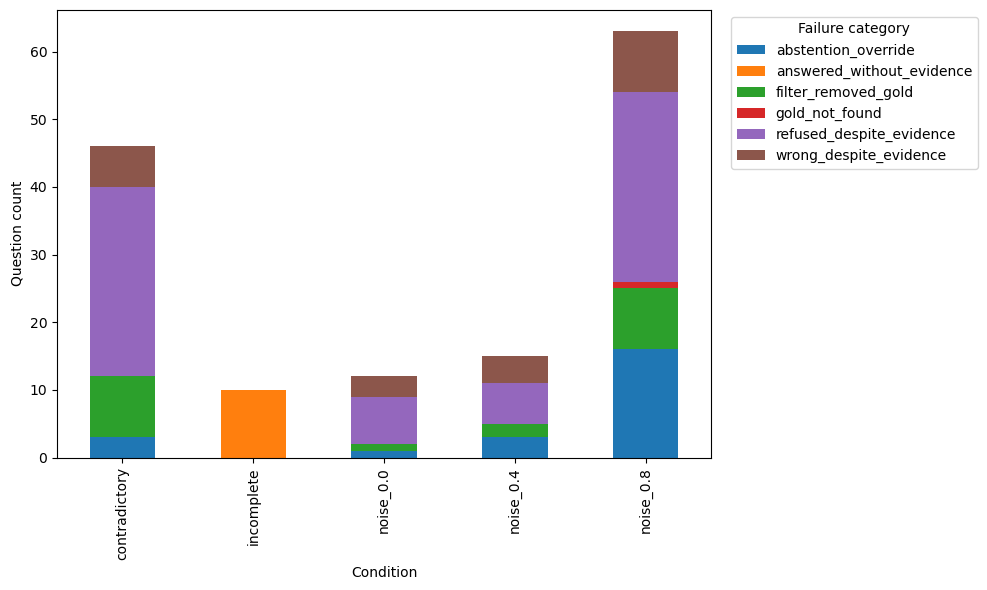

In [4]:
def reading_frame(rows):
    out = []
    for _, r in rows.iterrows():
        original = next(x for x in eval_rows if x["condition"] == r.condition and str(x["id"]) == str(r.id))
        passages = [{"score":s, "kept":i in json.loads(r.kept_indices), "text":p[:300]} for i,(p,s) in enumerate(zip(original["docs"], json.loads(r.scores)))]
        out.append({"condition":r.condition,"id":r.id,"query":r.query,"gold_answer":r.gold_answer,
                    "passages":json.dumps(passages, ensure_ascii=False),
                    "pred_E0":r.pred_E0,"pred_E2_filter_only":r.pred_E2_filter_only,
                    "pred_E0_abstain_only":r.pred_E0_abstain_only,"pred_E2_full":r.pred_E2_full,
                    "failure_category_E2_full":r.failure_category_E2_full,"failure_category_E2_filter_only":r.failure_category_E2_filter_only})
    return pd.DataFrame(out)
def show_example(condition, id):
    r = next(x for x in eval_rows if x["condition"] == condition and str(x["id"]) == str(id)); q = question_table[(question_table.condition==condition)&(question_table.id.astype(str)==str(id))].iloc[0]
    print(r["query"]); print("Gold:", r["answer"])
    for i,(p,s) in enumerate(zip(r["docs"], json.loads(q.scores))):
        print(f"\n[{i}] score={s:.12g} {'kept' if i in json.loads(q.kept_indices) else 'removed'} contains_gold={contains(p,r['answer'])}\n{p}")
    for v in prediction_sets: print(v, q[f"label_{v}"], q[f"pred_{v}"])
    print("best_score",q.best_score,"tau",tau,"filter_threshold",filter_threshold,"failure_category",q.failure_category_E2_full)
    if condition=="contradictory": print("true/fake/both kept",q.true_kept,q.fake_kept,q.both_kept)

def export(name, frame): frame.to_csv(E4_RESULTS / name, index=False)
export("e4_read_abstention_flips.csv", reading_frame(question_table[question_table.pred_E2_filter_only != question_table.pred_E2_full]))
export("e4_read_filter_losses.csv", reading_frame(question_table[(question_table.condition != "incomplete") & (question_table.label_E0=="correct") & (question_table.label_E2_filter_only!="correct")]))
gain_pool = question_table[(question_table.condition != "incomplete") & (question_table.label_E0!="correct") & (question_table.label_E2_filter_only=="correct")]
quotas = {c: 10 // len(gain_pool.condition.unique()) for c in gain_pool.condition.unique()}
for c in sorted(gain_pool.condition.unique())[:10 % len(quotas)]: quotas[c] += 1
gains = pd.concat([group.sample(n=min(quotas[c], len(group)), random_state=42) for c, group in gain_pool.groupby("condition")])
export("e4_read_filter_gains.csv", reading_frame(gains))
export("e4_read_incomplete_answered.csv", reading_frame(question_table[(question_table.condition=="incomplete") & (question_table.label_E2_full=="answered")]))
export("e4_read_contradictory_failures.csv", reading_frame(question_table[(question_table.condition=="contradictory") & (question_table.label_E2_full!="correct")]))

plot_data = cat_table[(cat_table.variant=="E2_full") & (cat_table["count"]>0)].pivot(index="condition", columns="category", values="count").fillna(0)
plot_data.plot(kind="bar", stacked=True, figsize=(10,6))
plt.xlabel("Condition"); plt.ylabel("Question count"); plt.legend(title="Failure category", bbox_to_anchor=(1.02,1), loc="upper left")
plt.tight_layout(); plt.savefig(E4_RESULTS / "e4_failure_categories.png", dpi=150); plt.show()


In [5]:
# Findings are calculated from the current test split.
display(pd.DataFrame({method: {"balanced": values["balanced"], "incomplete rejection": values["incomplete"]["rejection_rate"], "contradictory accuracy": values["contradictory"]["accuracy"]} for method, values in summaries.items()}).T.round(4))
display(question_table.loc[question_table["failure_category_E2_full"].ne(""), "failure_category_E2_full"].value_counts().rename("count"))


,balanced,incomplete rejection,contradictory accuracy
E0,0.8659,0.8524,0.5429
E2_filter_only,0.9111,0.9333,0.3857
E0_abstain_only,0.8817,0.9190,0.5000
E2_full,0.9048,0.9524,0.3429


failure_category_E2_full
refused_despite_evidence     69
abstention_override          23
wrong_despite_evidence       22
filter_removed_gold          21
answered_without_evidence    10
gold_not_found                1
Name: count, dtype: int64